# ¿Cuánto aviso nos da un río? · 07 — Chronos-2: predicciones de un modelo fundacional

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py` y `chronos2.py`; identificado como `v4` en el código y en las salidas), con las mismas emisiones de los cuadernos 05, 06 y 08. Chronos-2 es el modelo fundacional de series de tiempo del Lab 9_4 (*La siguiente generación: Transformers y modelos fundacionales*), usado con sus **pesos publicados, sin ajuste local**. La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P5** y prepara las predicciones de Chronos-2 que usa la comparación integrada del **08**, donde Chronos-2 es un **candidato más** en las selecciones finales (magnitud y avisos) junto a los seis modelos entrenados. Aquí solo se decide, **en validación**, lo que es propio de Chronos-2: el contexto y el pronóstico puntual (sección 3). Además se evalúa lo que solo tiene sentido para un pronóstico probabilístico (cobertura y CRPS de las bandas), la sensibilidad al contexto, el escenario idealizado con lluvia futura (aparte de toda selección) y Cirato (exploratorio).

**Predicciones guardadas:** pronosticar con 2 048 días de contexto toma más de una hora por combinación en CPU, por lo que los cuantiles se guardan en una caché. Una predicción guardada se reutiliza solo si coinciden su identidad completa (configuración, huella de los archivos del modelo, versiones de software, valores de entrada de cada emisión y fechas), su contenido es válido y una muestra de emisiones vuelta a pronosticar da lo mismo (sección 4); si no, se recalcula.

**Sobre el periodo de prueba:** las reglas se fijaron antes de la evaluación final (sección 0.3), pero el periodo de prueba se consultó durante el desarrollo del proyecto, y qué variables darle a Chronos-2 se decidió con los cuadernos 05 y 06: no es una prueba ciega.

---

## 0. Objetivo y decisiones de diseño

### 0.1 Pregunta
> **¿Qué pronósticos da un modelo fundacional, sin ajuste de sus pesos a estas cuencas, con las mismas entradas que reciben los modelos entrenados?** El 08 responde si es mejor que ellos; este cuaderno los produce y evalúa lo que es propio de un pronóstico probabilístico.

### 0.2 Qué es Chronos-2 (repaso del Lab 9_4)
| | |
|---|---|
| Arquitectura | Transformer **solo encoder** (como BERT), 120 M de parámetros. Agrupa la serie en **parches** de 16 días; cada parche es un *token*. |
| Covariables | **Atención de grupo**: la serie objetivo y sus covariables se miran entre sí dentro del mismo pronóstico. Así aprende *en contexto* (sin ajustar pesos) cómo una covariable anticipa al caudal. |
| Tipos de covariables | **Pasadas** (solo hasta t o t − 1: lluvia, índices, caudal aguas arriba) y **futuras** (de t+1 a t+30: solo la lluvia futura observada del escenario idealizado). |
| Salida | 21 cuantiles (1 % … 99 %) de cada uno de los 30 días, en una sola pasada. |
| Preentrenamiento | `autogluon/chronos_datasets`, `Salesforce/GiftEvalPretrain` y series sintéticas (ficha del modelo). No se sabe si incluye series del SENAMHI (0.4). |

### 0.3 Protocolo (fijado antes de ejecutar)
| Paso | Decisión |
|---|---|
| Emisiones | Racarumi y Tamshiyacu: las del cuaderno 06 (validación 2009–2015 y prueba 2016–fin). Con estaciones aguas arriba: las emisiones de Tamshiyacu con San Regis válido (y Requena válido para sus variantes), que contienen las filas de los cuadernos 05 y 08. Chronos-2 pronostica cada emisión por separado, así que una predicción vale para cualquier experimento que contenga esa emisión. |
| Combinaciones | Las de la comparación integrada del 08 (`entradas.DISENO_INTEGRADO`) que Chronos-2 puede recibir: **Q**; **Q+P**; **Q+P+IA** (la lluvia y los índices antecedentes IPA k = 0.90 y 0.97 y días secos como covariables pasadas); en Tamshiyacu, las 12 combinaciones de {—, P, P+IA} × {—, SR, RQ, SR+RQ} (San Regis, Requena o ambas); cada una con las fuentes externas **hasta t** y **hasta t−1** (el último día de cada covariable externa queda como desconocido). El caudal local siempre llega hasta t. |
| Entradas | Caudal en m³/s; lluvia de la cuenca PISCOp v2.1 e índices en mm/d (y días); caudal aguas arriba en m³/s. Cada serie se corta en su último día disponible para la emisión y **después** se interpolan, en log(Q + ε), solo los vacíos interiores de ≤ 3 días (así el relleno nunca usa datos posteriores a la emisión). Si hay un escalón de nivel dentro del contexto, se borran los días anteriores al último escalón ≤ t. Chronos-2 escala cada serie por sí mismo. |
| Representación | Chronos-2 recibe **la serie diaria completa** de cada covariable dentro de su contexto (512 o 2 048 días), no 7 días + 3 sumas como los modelos tabulares. Los índices antecedentes son funciones de la lluvia que Chronos-2 ya ve; se le dan igual para que cada combinación del 08 tenga su candidato con las mismas fuentes y disponibilidad (con la representación propia de Chronos-2). |
| Contexto y pronóstico puntual | En el **bloque de selección 2012–2015**, variante solo caudal: contexto de 512, 1024 o 2048 días × **mediana** o **media** (integral de los 21 cuantiles), con la regla de selección del estudio (bootstrap pareado de meses, margen ±0.01, el más simple entre equivalentes: contexto más corto y mediana). Se usa en todas las combinaciones de la estación. |
| Avisos | Trayectoria **mediana** (como en el cuaderno 04); la regla de avisos se calibra en el 08 con las demás configuraciones. |
| Pronóstico probabilístico | Cobertura de las bandas P10–P90 y P05–P95 (ideal 80 % y 90 %), también en los días sobre el P95, ancho de la banda y CRPS (que para un pronóstico de un solo valor es el error absoluto), con la persistencia como referencia. |

### 0.4 Advertencias
- **Contaminación de datos:** no se puede descartar que el preentrenamiento incluya series de caudal del Perú. CAMELS-PE v1.0.1 se publicó en 2026, después de Chronos-2 (octubre de 2025), pero los caudales del SENAMHI existen en otras fuentes.
- **Sin ajuste local no es "sin datos" ni "sin selección":** se usa la historia de la estación como contexto y se eligen en validación el contexto y el pronóstico puntual.
- **El escenario idealizado no es un pronóstico real:** la lluvia futura observada equivale a un pronóstico de lluvia perfecto; no participa en ninguna selección.

---
## 1. Configuración
Librerías, rutas y carga de Chronos-2. `chronos2.py` arma las entradas de cada emisión, pronostica, guarda los cuantiles en una caché local y calcula media, mediana, CRPS y cobertura.
**Pesos del modelo:** se buscan en la variable de entorno `CHRONOS2_MODELO`, luego en `_modelos_hf/chronos-2/` (raíz del repositorio, no se sube a GitHub) y, si no están, se descargan de Hugging Face (`amazon/chronos-2`, ~480 MB).

In [1]:
import os, sys, json, time, warnings, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import torch, chronos

import comun as C
import aguas_arriba as A
import lluvia as LL
import entradas as EN
import integrado as I
import chronos2 as CH

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'          # solo para probar el código: B mínimo y un solo contexto
B = 50 if RAPIDO else 1000

RUTA_SAL = C.ruta_salidas() / 'chronos'          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
PREVIAS = {k: C.verificar_resumen(C.ruta_salidas() / k / 'resumen.json') for k in ['racarumi', 'tamshiyacu', 'anticipacion', 'aguas_arriba', 'lluvia']}
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

EST = ['Racarumi', 'Tamshiyacu']
L, H = C.L_VENTANA, len(C.HORIZONTES)
V0, V1, V2, VL = LL.ESC_BASE, LL.ESC_OBS, LL.ESC_FUT, LL.ESC_LAT     # etiquetas de la caché (lluvia.py)
COLE = {'Racarumi': '#e07b00', 'Tamshiyacu': '#1f5fa8'}
H_CLAVE = {'Racarumi': [1, 2, 3, 5, 7, 15, 30], 'Tamshiyacu': [1, 3, 7, 15, 20, 30]}
CONTEXTOS = [512] if RAPIDO else [512, 1024, 2048]
PUNTOS = ['mediana', 'media']
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI): caudal observado depurado del EDA y lluvia PISCOp v2.1; Chronos-2 (amazon/chronos-2)'
T_INICIO = time.time()

PIPE, DISP = CH.cargar_modelo()
ORIGEN = CH.resolver_modelo()
HUELLA = CH.huella_modelo()          # SHA-256 de TODOS los archivos del modelo (pesos y configuración): identidad de la caché
HUELLA_PESOS = CH.huella_pesos()     # SHA-256 de model.safetensors, para comparar con la publicación
print(f"Ejecución: {datetime.now():%Y-%m-%d %H:%M} | Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"torch {torch.__version__} | chronos-forecasting {chronos.__version__} | dispositivo {DISP} ({torch.get_num_threads()} hilos) | "
      f"modo rápido: {RAPIDO}")
print(f"Chronos-2: {ORIGEN['origen']}{f" (commit {ORIGEN['commit']})" if ORIGEN['commit'] else ''} | {ORIGEN['ruta']} | SHA-256 de model.safetensors {HUELLA_PESOS[:16]}… | "
      f"huella de todos los archivos del modelo {HUELLA[:16]}… | {sum(p.numel() for p in PIPE.model.parameters()) / 1e6:.0f} M de parámetros")
print('Pesos usados tal como se publicaron: sin ajuste local (fine-tuning) a estas estaciones.')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]


Loading weights:  79%|███████▉  | 135/170 [00:00<00:00, 1349.14it/s]


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 1464.90it/s]

Ejecución: 2026-11-22 22:05 | Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | torch 2.14.1+cu130 | chronos-forecasting 2.3.2 | dispositivo cpu (2 hilos) | modo rápido: False
Chronos-2: local (_modelos_hf/chronos-2) | <raíz del repositorio>/_modelos_hf/chronos-2 | SHA-256 de model.safetensors ddcda3c7508bf252… | huella de todos los archivos del modelo 409cba0e01758f83… | 119 M de parámetros
Pesos usados tal como se publicaron: sin ajuste local (fine-tuning) a estas estaciones.


---
## 2. Datos y emisiones
(a) Las emisiones de cada estación se reconstruyen con el diseño del cuaderno 06 (`entradas.DISENO_LLUVIA`) y se comprueba que coinciden con las guardadas por el 06; (b) las emisiones de Tamshiyacu con San Regis válido (y Requena válido) forman un conjunto algo más amplio, el de las predicciones guardadas, y se comprueba que **contiene** el bloque de selección y la prueba de los cuadernos 05 y 08 (`entradas.DISENO_INTEGRADO`); (c) se cargan las estaciones aguas arriba y los índices antecedentes.
**Por qué:** Chronos-2 no se entrena, pero cada predicción debe existir para las emisiones exactas en que el 08 compara candidatos.

In [2]:
Z06 = np.load(C.ruta_salidas() / 'lluvia' / 'predicciones.npz')
Z05 = np.load(C.ruta_salidas() / 'aguas_arriba' / 'predicciones.npz')
D, filas_inv = {}, []
for e in EST:
    x = I.cargar(e, EN.DISENO_LLUVIA)
    m, p, VC = x.m, x.p, x.VC
    iv, ip = p['val'], p['pru']
    assert np.array_equal(m.fechas[iv].values.astype('datetime64[D]'), Z06[f'{e}|fechas_val']), f'{e}: validación distinta a la del cuaderno 06'
    assert np.array_equal(m.fechas[ip].values.astype('datetime64[D]'), Z06[f'{e}|Q|fechas_pru']), f'{e}: prueba distinta a la del cuaderno 06'
    assert np.allclose(m.q_obs[ip], Z06[f'{e}|Q|obs_pru']), f'{e}: observaciones distintas'
    D[e] = dict(x=x, q=x.F.q, eps=x.F.eps, esc=x.F.esc, P=x.F.P, IA=x.F.IA, P95=x.P95, m=m, p=p, VC=VC, iv=iv, ip=ip,
                F=m.fechas[np.concatenate([iv, ip])], Qin=CH.preparar(x.F.q, x.F.eps))
    filas_inv.append({'conjunto de emisiones': f'{e} (cuaderno 06)', 'validación': len(iv), 'bloque de selección 2012–2015': len(VC.sel),
                      'prueba': len(ip), 'periodo de prueba': f"{m.fechas[ip].min():%Y-%m-%d} a {m.fechas[ip].max():%Y-%m-%d}", 'escalones de nivel': len(x.F.esc)})

ARR = {}
for n in ['San Regis', 'Requena', 'Cirato']:
    qa, inf = A.cargar_arriba(n)
    eps_a = C.eps_entrenamiento(qa) if n != 'Cirato' else float(qa.mean() / 100)      # Cirato no tiene datos antes de 2022
    esc_a = C.escalones(qa) if n != 'Cirato' else pd.DatetimeIndex([])
    ARR[n] = dict(q=qa, eps=eps_a, esc=esc_a, Qin=CH.preparar(qa, eps_a), info=inf)

# Emisiones de Tamshiyacu con San Regis válido (conjunto de las predicciones guardadas)
dT = D['Tamshiyacu']
m_tot = C.construir_muestras(dT['q'], L=L, H=H, esc=dT['esc'], eps=dT['eps'])
p_tot = C.particion(m_tot)
ok = {n: A.ventanas_entrada(ARR[n]['q'], m_tot.fechas, L, ARR[n]['eps'], ARR[n]['esc'])[1] for n in ['San Regis', 'Requena']}
usar = np.zeros(len(m_tot.fechas), bool)
iev = np.concatenate([p_tot['ent'], p_tot['val']])
usar[iev] = ok['San Regis'][iev] & ok['Requena'][iev]
usar[p_tot['pru']] = ok['San Regis'][p_tot['pru']]
m5 = A.subconjunto(m_tot, np.where(usar)[0]); p5 = C.particion(m5); VC5 = C.ValidacionCausal(m5, p5['val'])
ok_rq5 = ok['Requena'][np.where(usar)[0]]
F_SEL5, F_EXT = VC5.fechas_sel, m5.fechas[p5['pru']]
F_COM = m5.fechas[p5['pru'][ok_rq5[p5['pru']]]]
F_SR, F_RQ = F_SEL5.append(F_EXT), F_SEL5.append(F_COM)
# Deben contener las emisiones del experimento de los cuadernos 05 y 08 (filas con San Regis y Requena válidos, también en t−1)
x8 = I.cargar('Tamshiyacu', EN.DISENO_INTEGRADO)
ip_rq = I.comunes(*[x8.D[k].ip for k in x8.D if EN.RQ in k[0]])          # prueba común con Requena del 05 y el 08 (Requena válida en t y t−1)
assert x8.VC.fechas_sel.isin(F_SEL5).all() and x8.m.fechas[x8.p['pru']].isin(F_EXT).all() and x8.m.fechas[ip_rq].isin(F_COM).all()
assert x8.VC.fechas_sel.isin(dT['F']).all() and x8.m.fechas[x8.p['pru']].isin(dT['F']).all(), 'las filas con San Regis deben estar en las del 06'
assert np.array_equal(x8.VC.fechas_sel.values.astype('datetime64[D]'), Z05['Tamshiyacu|fechas_sel']), 'bloque de selección distinto al del cuaderno 05'
for nom, f in [('Tamshiyacu con San Regis: selección 2012–2015 + prueba con San Regis', F_SR), ('Tamshiyacu con San Regis y Requena: selección 2012–2015 + prueba común con Requena', F_RQ)]:
    filas_inv.append({'conjunto de emisiones': nom, 'bloque de selección 2012–2015': len(F_SEL5), 'prueba': len(f) - len(F_SEL5),
                      'periodo de prueba': f"{f[len(F_SEL5):].min():%Y-%m-%d} a {f.max():%Y-%m-%d}"})
filas_inv.append({'conjunto de emisiones': 'Tamshiyacu, filas de los cuadernos 05 y 08 (contenidas en las anteriores)', 'validación': len(x8.p['val']),
                  'bloque de selección 2012–2015': len(x8.VC.sel), 'prueba': len(x8.p['pru']),
                  'periodo de prueba': f"{x8.m.fechas[x8.p['pru']].min():%Y-%m-%d} a {x8.m.fechas[x8.p['pru']].max():%Y-%m-%d} (con Requena: {len(ip_rq)})"})
inv = pd.DataFrame(filas_inv).set_index('conjunto de emisiones')
inv.to_csv(RUTA_TAB / 'tabla_emisiones.csv')
inv

,validación,bloque de selección 2012–2015,prueba,periodo de prueba,escalones de nivel
conjunto de emisiones,,,,,
Racarumi (cuaderno 06),2371.0,1369,2521,2016-01-01 a 2023-08-01,0.0
Tamshiyacu (cuaderno 06),2025.0,1195,3252,2016-01-01 a 2025-12-01,41.0
Tamshiyacu con San Regis: selección 2012–2015 + prueba con San Regis,NaN,1150,2819,2016-01-01 a 2025-12-01,NaN
Tamshiyacu con San Regis y Requena: selección 2012–2015 + prueba común con Requena,NaN,1150,1103,2016-01-01 a 2020-03-31,NaN
"Tamshiyacu, filas de los cuadernos 05 y 08 (contenidas en las anteriores)",1928.0,1138,2806,2016-01-01 a 2025-12-01 (con Requena: 1093),NaN


**Interpretación:**
- **Mismas emisiones que el cuaderno 06:** las fechas de validación y de prueba y los caudales observados coinciden con los guardados por el 06 (las comprobaciones de la celda no fallan). Racarumi: 2 371 emisiones de validación (1 369 en el bloque de selección) y 2 521 de prueba (2016-01 a 2023-08). Tamshiyacu: 2 025 y 3 252 (2016-01 a 2025-12).
- **Emisiones con estaciones aguas arriba:** el conjunto de las predicciones guardadas (San Regis válida: 1 150 de selección y 2 819 de prueba; con Requena: 1 103 de prueba). **Contienen** las filas de los cuadernos 05 y 08 (1 138 de selección, 2 806 de prueba y 1 093 en el periodo común con Requena, comprobado), así que el 08 toma de ellas exactamente las emisiones de su experimento.
- **Escalones:** Tamshiyacu tiene 41 escalones de nivel (hasta 2014) y San Regis 17. En esos años el contexto de Chronos-2 se corta en el último escalón; esto importa en las secciones 3 y 6.

---
## 3. ¿Cuánta historia necesita? Elección del contexto y del pronóstico puntual
Con la variante solo caudal se pronostica el bloque de selección 2012–2015 con contextos de 512, 1024 y 2048 días y se aplica la regla de selección del estudio a seis candidatos (3 contextos × mediana o media). El orden de simplicidad es: contexto más corto primero y, a igual contexto, la mediana.
**Por qué:** es el único "hiperparámetro" de un modelo sin ajuste local. Un contexto largo deja ver varios años hidrológicos; uno corto pesa más lo reciente. La media debería dar menor error cuadrático que la mediana cuando la distribución es asimétrica (crecidas). Es lo único que se elige en este cuaderno, y se elige en validación.

In [3]:
CLAVES_USADAS = []        # auditoría de la caché: (estación, variante, emisiones, reutilizada, validación, reproducción)
MUESTRA_REPRODUCCION = 8  # emisiones al azar (más la primera y la última) que se vuelven a pronosticar en cada caché reutilizada

def pronostico(e, var, fechas, contexto, pasadas=None, futuras=None, cortes=None, ocultar=None):
    "Cuantiles (n, 30, 21) de Chronos-2 para las fechas dadas (caché con identidad completa)."
    d = D[e]
    clave = dict(estacion=e, variante=var, contexto=contexto, modelo=HUELLA, entradas=sorted((pasadas or {}).keys()),
                 futuras=futuras, ocultar=ocultar, version=1)
    ins = CH.entradas(fechas, d['Qin'], contexto, pasadas=pasadas, futuras=futuras,
                      cortes={'objetivo': d['esc'], **(cortes or {})}, ocultar=ocultar, H=H)
    calcular = lambda: CH.pronosticar(PIPE, ins, H, etiqueta=f'{e} · {var} · contexto {contexto} d')
    # Una caché se reutiliza solo si su identidad es idéntica, su contenido es válido (forma, finitud, ≥ 0,
    # cuantiles ordenados) y una muestra de emisiones vuelta a pronosticar ahora coincide con lo guardado
    reproducir = lambda Q: CH.reproducir_muestra(PIPE, ins, Q, k=MUESTRA_REPRODUCCION, semilla=C.SEMILLA, H=H)
    det = {}
    Q, leido = CH.con_cache_info(clave, fechas, calcular, entradas=ins, H=H, reproducir=reproducir, detalle=det)
    rep = det.get('reproduccion') or {}
    CLAVES_USADAS.append({'estación': e, 'variante (clave de caché)': var, 'contexto (d)': contexto, 'emisiones': len(fechas),
                          'reutilizada de la caché': leido, 'estado de la caché': det['motivo'], 'archivo creado': det.get('creada'),
                          'emisiones reproducidas': rep.get('emisiones_reproducidas'), 'dif. relativa máx.': rep.get('dif_relativa_max')})
    return Q

CTX, PT, TAB_CTX = {}, {}, {}
for e in EST:
    VC = D[e]['VC']
    cand = {}
    for ctx in CONTEXTOS:
        Q = pronostico(e, V0, VC.fechas_sel, ctx)
        for pt in PUNTOS:
            cand[f'{ctx} d · {pt}'] = CH.punto(Q, pt)
    orden = [f'{c} d · {pt}' for c in CONTEXTOS for pt in PUNTOS]
    tab, s, mj = C.seleccion_pareada(VC.fechas_sel, VC.obs_sel, cand, B=B, orden=orden)
    CTX[e], PT[e] = int(s.split(' d')[0]), s.split('· ')[1]
    tab.insert(0, 'estación', e)
    TAB_CTX[e] = tab
    print(f'{e}: mejor {mj} | seleccionado {s}')
tab_ctx = pd.concat(TAB_CTX.values()).reset_index().set_index(['estación', 'modelo']).rename_axis(['estación', 'candidato'])
tab_ctx.to_csv(RUTA_TAB / 'tabla_contexto.csv')
tab_ctx.round(4)

Racarumi: mejor 2048 d · media | seleccionado 2048 d · media


Tamshiyacu: mejor 2048 d · media | seleccionado 512 d · media


NSE medio selección  diferencia con el mejor  \
estación   candidato                                                        
Racarumi   2048 d · media                 0.5957                   0.0000   
           1024 d · media                 0.5671                  -0.0286   
           2048 d · mediana               0.5495                  -0.0461   
           512 d · media                  0.5308                  -0.0648   
           1024 d · mediana               0.5138                  -0.0819   
           512 d · mediana                0.4789                  -0.1168   
Tamshiyacu 2048 d · media                 0.8699                   0.0000   
           1024 d · media                 0.8699                  -0.0000   
           512 d · media                  0.8687                  -0.0011   
           2048 d · mediana               0.8679                  -0.0020   
           1024 d · mediana               0.8679                  -0.0020   
           512 d · mediana                0.8665                  -0.0034   

                             IC90 inferior  IC90 superior        clase  \
estación   candidato                                                     
Racarumi   2048 d · media              NaN            NaN        mejor   
           1024 d · media          -0.0617        -0.0037         peor   
           2048 d · mediana        -0.0725        -0.0097         peor   
           512 d · media           -0.1438         0.0087   inconcluso   
           1024 d · mediana        -0.1272        -0.0411         peor   
           512 d · mediana         -0.2037        -0.0338         peor   
Tamshiyacu 2048 d · media              NaN            NaN        mejor   
           1024 d · media          -0.0000         0.0000  equivalente   
           512 d · media           -0.0033         0.0003  equivalente   
           2048 d · mediana        -0.0075         0.0019  equivalente   
           1024 d · mediana        -0.0075         0.0019  equivalente   
           512 d · mediana         -0.0101         0.0015   inconcluso   

                             seleccionado  
estación   candidato                       
Racarumi   2048 d · media            True  
           1024 d · media           False  
           2048 d · mediana         False  
           512 d · media            False  
           1024 d · mediana         False  
           512 d · mediana          False  
Tamshiyacu 2048 d · media           False  
           1024 d · media           False  
           512 d · media             True  
           2048 d · mediana         False  
           1024 d · mediana         False  
           512 d · mediana          False

**Interpretación:**
- **Racarumi necesita mucha historia:** el NSE medio sube con el contexto (media: 0.531 con 512 días, 0.567 con 1 024 y **0.596 con 2 048**) y los demás candidatos quedan peores o inconclusos. Se elige **2 048 días (≈ 5.6 años) y la media**.
- **La media es mejor que la mediana** (~0.05 de NSE medio en Racarumi con cada contexto): en un río con crecidas la distribución es asimétrica y el NSE castiga los errores grandes.
- **Tamshiyacu no distingue contextos:** los seis candidatos quedan entre 0.866 y 0.870 y 1 024 y 2 048 días dan el mismo resultado, porque en 2012–2015 el contexto se corta en el último escalón de nivel. La regla elige el más simple equivalente: **512 días y la media**. Esta limitación se revisa en la sección 6.
- Esta es la única elección propia de Chronos-2 y se hace solo con el bloque de selección; se usa en todas las combinaciones de cada estación.

---
## 4. Predicciones para la comparación integrada y verificación de las predicciones guardadas
Con el contexto y el pronóstico puntual elegidos se pronostican las combinaciones que necesita el 08 (más el escenario idealizado y Cirato, que se evalúan aparte). **Antes de pronosticar** se comprueba si la caché tiene una predicción **verificada** de cada una (`chronos2.con_cache_info`): (i) identidad completa idéntica (configuración, huella del modelo, versiones, valores de entrada de cada emisión y fechas); (ii) contenido válido (forma emisiones × 30 × 21, valores finitos y ≥ 0, cuantiles ordenados; `chronos2.validar_contenido`); y (iii) reproducción: se vuelven a pronosticar ahora 8 emisiones al azar más la primera y la última y se comparan con lo guardado (`chronos2.reproducir_muestra`, diferencia relativa ≤ 2·10⁻³). Una caché que falla cualquiera de las tres, o que no se puede leer, se descarta, se registra y se recalcula; las que faltan se calculan. Lo mismo vale para las cachés del contexto (sección 3). También se comprueba que el contexto termina en t, que la lluvia «hasta t − 1» tiene desconocido solo el día t y que la lluvia futura empieza en t + 1.
**Claves de caché:** algunas combinaciones conservan un nombre descriptivo (por ejemplo, «+ San Regis y lluvia» es Q+P+SR); las demás se nombran con la etiqueta de `integrado.py`. La tabla muestra ambas.

In [4]:
for e in EST:
    d, F, ctx = D[e], D[e]['F'], CTX[e]
    ins = CH.entradas(F[:3], d['Qin'], ctx, pasadas={'P': d['P']}, ocultar={'P': 1}, cortes={'objetivo': d['esc']})
    assert np.allclose(ins[0]['target'][-1], d['q'].loc[F[0]]) and np.isnan(ins[0]['past_covariates']['P'][-1])
    assert np.allclose(ins[0]['past_covariates']['P'][-2], d['P'].loc[F[0] - pd.Timedelta(days=1)])
    ins = CH.entradas(F[:3], d['Qin'], ctx, pasadas={'P': d['P']}, futuras=['P'])
    assert np.allclose(ins[0]['future_covariates']['P'][0], d['P'].loc[F[0] + pd.Timedelta(days=1)]), 'la lluvia futura empieza en t + 1'

def fuentes(e, conj):
    "Covariables pasadas de un conjunto: lluvia, índices antecedentes y caudal aguas arriba (con su ε para el relleno causal)."
    d, out = D[e], {}
    for f in EN.fichas(conj):
        if f == 'P':
            out['P'] = d['P']
        elif f == 'IA':
            out.update({c: d['IA'][c] for c in d['IA'].columns})
        elif f.startswith('A:'):
            out[f[2:]] = ARR[f[2:]]['Qin']
    return out

# (estación, conjunto, latencia, clave de caché, emisiones, futuras)
NOMBRE_R4 = {('Q', 0): V0, ('Q+P', 0): V1, ('Q+P', 1): VL, ('Q+' + EN.SR, 0): '+ San Regis', ('Q+P+' + EN.SR, 0): '+ San Regis y lluvia',
             ('Q+' + EN.RQ, 0): '+ Requena', ('Q+' + EN.SR + '+' + EN.RQ, 0): '+ San Regis y Requena'}
PLAN = []
for e in EST:
    for conj, lat in EN.DISENO_INTEGRADO[e]['conjuntos']:
        if e == 'Tamshiyacu' and conj in ('Q', 'Q+P') and lat == 0:
            fechas, grupo = D[e]['F'], 'cuaderno 06'                 # predicciones guardadas en todas las emisiones del 06
        elif e == 'Tamshiyacu':
            fechas, grupo = (F_RQ, 'con Requena') if EN.RQ in conj else (F_SR, 'con San Regis')
        else:
            fechas, grupo = D[e]['F'], 'cuaderno 06'
        etq = NOMBRE_R4.get((conj, lat)) if not (e == 'Tamshiyacu' and (conj, lat) == ('Q+P', 1)) else None
        PLAN.append(dict(estacion=e, conj=conj, lat=lat, clave=etq or I.etiqueta(conj, lat), fechas=fechas, grupo=grupo, futuras=None))
    PLAN.append(dict(estacion=e, conj='Q+P', lat=0, clave=V2, fechas=D[e]['F'], grupo='cuaderno 06', futuras=['P'], idealizado=True))
F_CI = None
dR = D['Racarumi']
fR = dR['m'].fechas[dR['ip']]
_, ok_c = A.ventanas_entrada(ARR['Cirato']['q'], fR, L, ARR['Cirato']['eps'])
F_CI = fR[ok_c & (fR >= '2022-10-01')]
PLAN.append(dict(estacion='Racarumi', conj='Q+A:Cirato', lat=0, clave='+ Cirato', fechas=F_CI, grupo='prueba con Cirato (exploratorio)', futuras=None))

cortes_a = {n: ARR[n]['esc'] for n in ['San Regis', 'Requena']}
QV, FV, filas_plan = {}, {}, []
for it in PLAN:
    e, conj, lat = it['estacion'], it['conj'], it['lat']
    pas = fuentes(e, conj)
    kw = dict(pasadas=pas or None, futuras=it['futuras'],
              cortes=cortes_a if any(k in pas for k in cortes_a) else None,
              ocultar={k: 1 for k in pas} if lat else None)
    n0 = len(CLAVES_USADAS)
    QV[(e, conj, lat, bool(it.get('idealizado')))] = pronostico(e, it['clave'], it['fechas'], CTX[e], **kw)
    FV[(e, conj, lat, bool(it.get('idealizado')))] = it['fechas']
    usada = CLAVES_USADAS[n0]
    rep = usada['dif. relativa máx.']
    filas_plan.append({'estación': e, 'conjunto': I.etiqueta(conj, lat) + (' + lluvia futura (idealizado)' if it.get('idealizado') else ''),
                       'covariables pasadas': ', '.join(pas) or '—', 'última fecha de las covariables': ('t−1' if lat else 't') if pas else '—',
                       'emisiones': len(it['fechas']), 'conjunto de emisiones': it['grupo'], 'clave de caché': it['clave'],
                       'reutilizada (identidad, contenido y reproducción verificados)': usada['reutilizada de la caché'],
                       'estado de la caché': usada['estado de la caché'], 'archivo creado': usada['archivo creado'],
                       'reproducción por muestreo': (f"{usada['emisiones reproducidas']} emisiones, dif. rel. máx. {rep:.1e}"
                                                     if rep is not None else 'calculada ahora (no aplica)')})
plan = pd.DataFrame(filas_plan).set_index(['estación', 'conjunto'])
plan.to_csv(RUTA_TAB / 'tabla_auditoria_cache.csv')
COL_R = 'reutilizada (identidad, contenido y reproducción verificados)'
print(f"Combinaciones: {len(plan)} | reutilizadas: {int(plan[COL_R].sum())} | "
      f"calculadas en esta ejecución: {int((~plan[COL_R]).sum())} | descartadas por contenido o reproducción: "
      f"{int(plan['estado de la caché'].str.startswith('descartada').sum())}")
# Todas las cachés de la ejecución (también las del contexto, sección 3) pasaron identidad, contenido y reproducción
aud = pd.DataFrame(CLAVES_USADAS)
aud.to_csv(RUTA_TAB / 'tabla_auditoria_cache_completa.csv', index=False)
assert (aud.loc[aud['reutilizada de la caché'], 'dif. relativa máx.'] <= 2e-3).all()
plan.drop(columns=['clave de caché'])

Combinaciones: 31 | reutilizadas: 31 | calculadas en esta ejecución: 0 | descartadas por contenido o reproducción: 0


covariables pasadas  \
estación   conjunto                                                                              
Racarumi   Q                                                                                 —   
           Q+P                                                                               P   
           Q+P (t−1)                                                                         P   
           Q+P+IA                            P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P+IA (t−1)                      P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P + lluvia futura (idealizado)                                                  P   
Tamshiyacu Q                                                                                 —   
           Q+P                                                                               P   
           Q+P (t−1)                                                                         P   
           Q+P+IA                            P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P+IA (t−1)                      P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+SR                                                                      San Regis   
           Q+SR (t−1)                                                                San Regis   
           Q+P+SR                                                                 P, San Regis   
           Q+P+SR (t−1)                                                           P, San Regis   
           Q+P+IA+SR                         P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P+IA+SR (t−1)                   P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+RQ                                                                        Requena   
           Q+RQ (t−1)                                                                  Requena   
           Q+P+RQ                                                                   P, Requena   
           Q+P+RQ (t−1)                                                             P, Requena   
           Q+P+IA+RQ                         P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P+IA+RQ (t−1)                   P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+SR+RQ                                                          San Regis, Requena   
           Q+SR+RQ (t−1)                                                    San Regis, Requena   
           Q+P+SR+RQ                                                     P, San Regis, Requena   
           Q+P+SR+RQ (t−1)                                               P, San Regis, Requena   
           Q+P+IA+SR+RQ                      P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P+IA+SR+RQ (t−1)                P, IPA k=0.90, IPA k=0.97, días secos consecut...   
           Q+P + lluvia futura (idealizado)                                                  P   
Racarumi   Q+C                                                                          Cirato   

                                            última fecha de las covariables  \
estación   conjunto                                                           
Racarumi   Q                                                              —   
           Q+P                                                            t   
           Q+P (t−1)                                                    t−1   
           Q+P+IA                                                         t   
           Q+P+IA (t−1)                                                 t−1   
           Q+P + lluvia futura (idealizado)                               t   
Tamshiyacu Q                                                              —   
           Q+P                                                            t   
           Q+P (t−1)                              

**Interpretación (verificación de las predicciones guardadas):**
- **31 combinaciones:** las 28 de la comparación integrada del 08 —5 en Racarumi (Q, Q+P, Q+P+IA y sus versiones hasta t−1) y 23 en Tamshiyacu (las 12 combinaciones de {—, P, P+IA} × {—, SR, RQ, SR+RQ}, cada una con las fuentes hasta t y hasta t−1, salvo Q)—, el escenario idealizado en cada estación y Cirato.
- **Las 31 se reutilizaron tras tres comprobaciones:** cada archivo pasó (i) la identidad completa (configuración, huella del modelo, versiones, valores de entrada de cada emisión y fechas), (ii) la validación de su contenido (forma emisiones × 30 × 21, valores finitos y ≥ 0, cuantiles ordenados) y (iii) la **reproducción**: se volvieron a pronosticar 10 emisiones (8 al azar, la primera y la última) y se compararon con lo guardado. La mayor diferencia relativa fue **6.7·10⁻⁷** (redondeo de float32 entre lotes de distinto tamaño), frente a la tolerancia de 2·10⁻³. Con las 6 cachés del contexto (sección 3), **37 cachés verificadas, ninguna descartada**.
- **Procedencia (columna «archivo creado»):** las predicciones se calcularon entre el 18 y el 22 de noviembre de 2026 a medida que se agregaban combinaciones al estudio (con 2 048 días de contexto, más de una hora por combinación en Racarumi; 4–14 minutos en Tamshiyacu). La ejecución final las leyó todas tras verificarlas.
- **Comprobaciones:** el contexto termina en Q(t); con las fuentes hasta t−1 el último día de cada covariable queda desconocido; la lluvia futura del idealizado empieza en t + 1.
- **Entradas reales (tabla siguiente):** Chronos-2 recibe la serie del caudal de la estación y cada fuente externa como **serie diaria en unidades físicas** (caudal en m³/s, lluvia en mm/d, IPA en mm, días secos en días), no en logaritmos ni como las variables construidas de los modelos entrenados. Los vacíos ≤ 3 días de los caudales se interpolan en log(Q + ε) solo con datos hasta el corte y se devuelven a m³/s; antes del último escalón de nivel de cada caudal (Tamshiyacu, San Regis, Requena) los días van como desconocidos. Con un día de retraso, el día t de cada covariable va como desconocido (comprobado en la primera emisión de cada combinación).

**Entradas reales de Chronos-2 por combinación.** La tabla siguiente se construye a partir de las entradas que efectivamente recibió el modelo (`chronos2.entradas`), no de una descripción: nombre y unidad de cada serie, días de contexto, último día disponible de cada covariable y tratamiento de vacíos y escalones. Chronos-2 recibe **series diarias en unidades físicas** (caudal en m³/s, lluvia en mm/d, IPA en mm, días secos en días) y las escala internamente; no recibe logaritmos ni las variables construidas de los modelos ajustados (acumulados, cambios, calendario). La comprueba un control: para cada combinación se reconstruye la primera emisión y se verifica que el último día disponible coincide con el declarado.

In [5]:
UNIDAD = {'P': 'lluvia de la cuenca P (mm/d)', 'IPA k=0.90': 'IPA k=0.90 (mm)', 'IPA k=0.97': 'IPA k=0.97 (mm)',
          'días secos consecutivos': 'días secos consecutivos (d)', 'San Regis': 'caudal de San Regis (m³/s)',
          'Requena': 'caudal de Requena (m³/s)', 'Cirato': 'caudal de Cirato (m³/s)'}
filas_ent = []
for it in PLAN:
    e, conj, lat = it['estacion'], it['conj'], it['lat']
    pas = fuentes(e, conj)
    f0 = pd.DatetimeIndex(it['fechas'][:1])
    cort = cortes_a if any(k in pas for k in cortes_a) else {}          # los mismos cortes que en la celda anterior
    ins0 = CH.entradas(f0, D[e]['Qin'], CTX[e], pasadas=pas or None, futuras=it['futuras'],
                       cortes={'objetivo': D[e]['esc'], **cort}, ocultar={k: 1 for k in pas} if lat else None, H=H)[0]
    assert len(ins0['target']) == CTX[e] and np.isfinite(ins0['target'][-1])
    for k, v in ins0.get('past_covariates', {}).items():
        if lat:
            assert np.isnan(v[-1]) and (np.isfinite(v[-2]) or k in ARR), (e, conj, k)     # t−1: el día t va como desconocido
        else:
            assert np.isfinite(v[-1]) or k in ARR, (e, conj, k)                          # hasta t: lluvia e índices observados en t
    esc_cov = [k for k in pas if k in cort]
    filas_ent.append({'estación': e, 'conjunto': I.etiqueta(conj, lat) + (' + lluvia futura (idealizado)' if it.get('idealizado') else ''),
                      'objetivo (contexto)': f"caudal de {e} (m³/s), {CTX[e]} días hasta t",
                      'covariables pasadas': '; '.join(UNIDAD.get(k, k) for k in pas) or '—',
                      'último día de las covariables': ('t − 1 (el día t va como desconocido)' if lat else 't') if pas else '—',
                      'covariables futuras': 'P observada t+1…t+30 (no disponible al emitir)' if it['futuras'] else '—',
                      'vacíos': 'caudales: ≤ 3 d interpolados en log(Q+ε) solo con datos hasta el corte; el resto, NaN' +
                                ('; lluvia e índices sin vacíos' if any(k in ('P', 'IPA k=0.90') for k in pas) else ''),
                      'escalones de nivel': 'días anteriores al último escalón ≤ t en NaN: ' + ', '.join([e] + esc_cov),
                      'pronóstico usado': f"{PT[e]} de 21 cuantiles, t+1…t+{H}"})
tab_ent = pd.DataFrame(filas_ent).set_index(['estación', 'conjunto'])
tab_ent.to_csv(RUTA_TAB / 'tabla_entradas_chronos.csv')
tab_ent

objetivo (contexto)  \
estación   conjunto                                                                          
Racarumi   Q                                  caudal de Racarumi (m³/s), 2048 días hasta t   
           Q+P                                caudal de Racarumi (m³/s), 2048 días hasta t   
           Q+P (t−1)                          caudal de Racarumi (m³/s), 2048 días hasta t   
           Q+P+IA                             caudal de Racarumi (m³/s), 2048 días hasta t   
           Q+P+IA (t−1)                       caudal de Racarumi (m³/s), 2048 días hasta t   
           Q+P + lluvia futura (idealizado)   caudal de Racarumi (m³/s), 2048 días hasta t   
Tamshiyacu Q                                 caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P                               caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P (t−1)                         caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA                            caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA (t−1)                      caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+SR                              caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+SR (t−1)                        caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+SR                            caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+SR (t−1)                      caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+SR                         caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+SR (t−1)                   caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+RQ                              caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+RQ (t−1)                        caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+RQ                            caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+RQ (t−1)                      caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+RQ                         caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+RQ (t−1)                   caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+SR+RQ                           caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+SR+RQ (t−1)                     caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+SR+RQ                         caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+SR+RQ (t−1)                   caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+SR+RQ                      caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P+IA+SR+RQ (t−1)                caudal de Tamshiyacu (m³/s), 512 días hasta t   
           Q+P + lluvia futura (idealizado)  caudal de Tamshiyacu (m³/s), 512 días hasta t   
Racarumi   Q+C                                caudal de Racarumi (m³/s), 2048 días hasta t   

                                                                           covariables pasadas  \
estación   conjunto                                                                              
Racarumi   Q                                                                                 —   
           Q+P                                                    lluvia de la cuenca P (mm/d)   
           Q+P (t−1)                                              lluvia de la cuenca P (mm/d)   
           Q+P+IA                            lluvia de la cuenca P (mm/d); IPA k=0.90 (mm);...   
           Q+P+IA (t−1)                      lluvia de la cuenca P (mm/d); IPA k=0.90 (mm);...   
           Q+P + lluvia futura (idealizado)                       lluvia de la cuenca P (mm/d)   
Tamshiyacu Q                                                                                 —   
           Q+P                                                    lluvia de la cuenca 

In [6]:
def sub(e, conj, lat, fechas, cual='punto', idealizado=False):
    "Pronóstico de una combinación en las fechas pedidas: 'punto' (media o mediana elegida), 'mediana' o 'cuantiles'."
    k = (e, conj, lat, idealizado)
    pos = FV[k].get_indexer(pd.DatetimeIndex(fechas))
    assert (pos >= 0).all(), k
    Q = QV[k][pos]
    return Q if cual == 'cuantiles' else CH.punto(Q, PT[e] if cual == 'punto' else cual)

# Archivo para el 08: por combinación, fechas de emisión, pronóstico puntual elegido, mediana y banda P10–P90
guardar = {'contexto': np.array([f'{e}:{CTX[e]}' for e in EST]), 'punto': np.array([f'{e}:{PT[e]}' for e in EST])}
for (e, conj, lat, ide), Q in QV.items():
    k = f"{e}|{I.etiqueta(conj, lat)}" + ('|idealizado' if ide else '')
    guardar[f'{k}|fechas'] = FV[(e, conj, lat, ide)].values.astype('datetime64[D]')
    guardar[f'{k}|punto'] = CH.punto(Q, PT[e]).astype('float32')
    guardar[f'{k}|mediana'] = CH.punto(Q, 'mediana').astype('float32')
    guardar[f'{k}|P10'] = CH.cuantil(Q, 0.1).astype('float32')
    guardar[f'{k}|P90'] = CH.cuantil(Q, 0.9).astype('float32')
np.savez_compressed(RUTA_SAL / 'predicciones.npz', **guardar)
print(f"{len(QV)} combinaciones guardadas en predicciones.npz ({sum(1 for k in guardar if k.endswith('|punto'))} con pronóstico puntual)")

31 combinaciones guardadas en predicciones.npz (31 con pronóstico puntual)


---
## 5. Pronóstico probabilístico (lo que un modelo de un solo valor no da)
En la prueba de cada estación (emisiones del 06), para solo caudal y + lluvia observada hasta t: (a) **cobertura** de las bandas P10–P90 y P05–P95 por horizonte (ideal 80 % y 90 %), también solo en los días con caudal observado sobre el P95; (b) **ancho medio** de la banda P10–P90; (c) **CRPS** medio por horizonte y su habilidad frente al error absoluto de la persistencia (CRPSS = 1 − CRPS / MAE de la persistencia; > 0: mejor que repetir el caudal de hoy).
**Por qué:** es el aporte propio de un pronóstico probabilístico. La comparación de su pronóstico puntual con los modelos entrenados está en el 08; la de sus bandas con la banda climatológica, en el 09.

In [7]:
hh = np.array(C.HORIZONTES)
filas_p, CRPS, COB = [], {}, {}
VAR_P = [('Q', 0, False, V0), ('Q+P', 0, False, V1)]
for e in EST:
    d = D[e]; m, ip = d['m'], d['ip']
    obs, fp = m.q_obs[ip], m.fechas[ip]
    mae_p = np.abs(obs - C.pred_persistencia(m, ip)).mean(0)
    alto = obs > d['P95']
    for conj, lat, ide, et in VAR_P:
        Q = sub(e, conj, lat, fp, 'cuantiles', ide)
        cr = CH.crps(obs, Q).mean(0)
        dentro = (obs >= CH.cuantil(Q, 0.1)) & (obs <= CH.cuantil(Q, 0.9))
        CRPS[(e, et)] = pd.DataFrame({'CRPS (m³/s)': cr, 'MAE persistencia (m³/s)': mae_p, 'CRPSS frente a la persistencia': 1 - cr / mae_p}, index=pd.Index(hh, name='h'))
        COB[(e, et)] = pd.DataFrame({'P10–P90': CH.cobertura(obs, Q, 0.1, 0.9), 'P05–P95': CH.cobertura(obs, Q, 0.05, 0.95),
                                     'P10–P90 en días > P95': [dentro[alto[:, j], j].mean() if alto[:, j].any() else np.nan for j in range(H)],
                                     'días > P95': alto.sum(0), 'ancho medio P10–P90 (m³/s)': (CH.cuantil(Q, 0.9) - CH.cuantil(Q, 0.1)).mean(0)},
                                    index=pd.Index(hh, name='h'))
        for h in H_CLAVE[e]:
            filas_p.append({'estación': e, 'variante': et, 'h': h, **COB[(e, et)].loc[h].to_dict(), **CRPS[(e, et)].loc[h].to_dict()})
prob = pd.DataFrame(filas_p).set_index(['estación', 'variante', 'h'])
prob.to_csv(RUTA_TAB / 'tabla_probabilistico.csv')
prob.round(3)

P10–P90  \
estación   variante                                           h             
Racarumi   Solo caudal                                        1     0.779   
                                                              2     0.792   
                                                              3     0.794   
                                                              5     0.781   
                                                              7     0.778   
                                                              15    0.770   
                                                              30    0.783   
           + lluvia observada hasta t (disponibilidad supu... 1     0.759   
                                                              2     0.768   
                                                              3     0.775   
                                                              5     0.762   
                                                              7     0.753   
                                                              15    0.753   
                                                              30    0.767   
Tamshiyacu Solo caudal                                        1     0.621   
                                                              3     0.810   
                                                              7     0.780   
                                                              15    0.761   
                                                              20    0.751   
                                                              30    0.740   
           + lluvia observada hasta t (disponibilidad supu... 1     0.736   
                                                              3     0.845   
                                                              7     0.814   
                                                              15    0.769   
                                                              20    0.762   
                                                              30    0.751   

                                                                  P05–P95  \
estación   variante                                           h             
Racarumi   Solo caudal                                        1     0.878   
                                                              2     0.881   
                                                              3     0.891   
                                                              5     0.891   
                                                              7     0.891   
                                                              15    0.887   
                                                              30    0.888   
           + lluvia observada hasta t (disponibilidad supu... 1     0.861   
                                                              2     0.871   
                                                              3     0.881   
                                                              5     0.884   
                                                              7     0.878   
                                                              15    0.868   
                                                              30    0.868   
Tamshiyacu Solo caudal                                        1     0.832   
                                                              3     0.923   
                                                              7     0.905   
                                                              15    0.875   
                                                              20    0.869   
                                                              30    0.860   
           + lluvia observada hasta t (disponibilidad supu... 1     0.891   
                                                              3     0.944   
                                                             

**Interpretación (prueba, emisiones del 06):**
- **Racarumi: cobertura agregada cercana a la nominal, pero no en las crecidas.** La banda P10–P90 contiene el observado el 77–79 % de las veces (ideal 80 %) y la P05–P95 el 88–89 % (ideal 90 %) en todos los horizontes; con la lluvia quedan algo estrechas (75–78 %). **En los días sobre el P95 la cobertura baja a 42–57 %**: el observado queda por encima del P90. Una cobertura agregada cercana a 80 % no demuestra una calibración adecuada en las condiciones que importan para los avisos. (Las bandas son intervalos **predictivos del caudal**; los IC 90 % del proyecto son intervalos de confianza **de las métricas**.)
- **El CRPS de Chronos-2 es 31–52 % menor que el error absoluto de la persistencia** en Racarumi y 36–49 % en Tamshiyacu (CRPSS > 0 en todos los horizontes): la distribución completa informa más que repetir el caudal de hoy. No es una comparación con los modelos entrenados: la de su valor central está en el 08.
- **Tamshiyacu: a 1 día las bandas son demasiado estrechas** (62 % de cobertura sin lluvia, 74 % con lluvia); entre 3 y 30 días la cobertura va de 74 a 85 %.

**Figura 1.** (a, b) Cobertura de la banda P10–P90 por horizonte (ideal 80 %; punteada: solo días sobre el P95); (c, d) habilidad del CRPS de Chronos-2 frente al error absoluto de la persistencia.

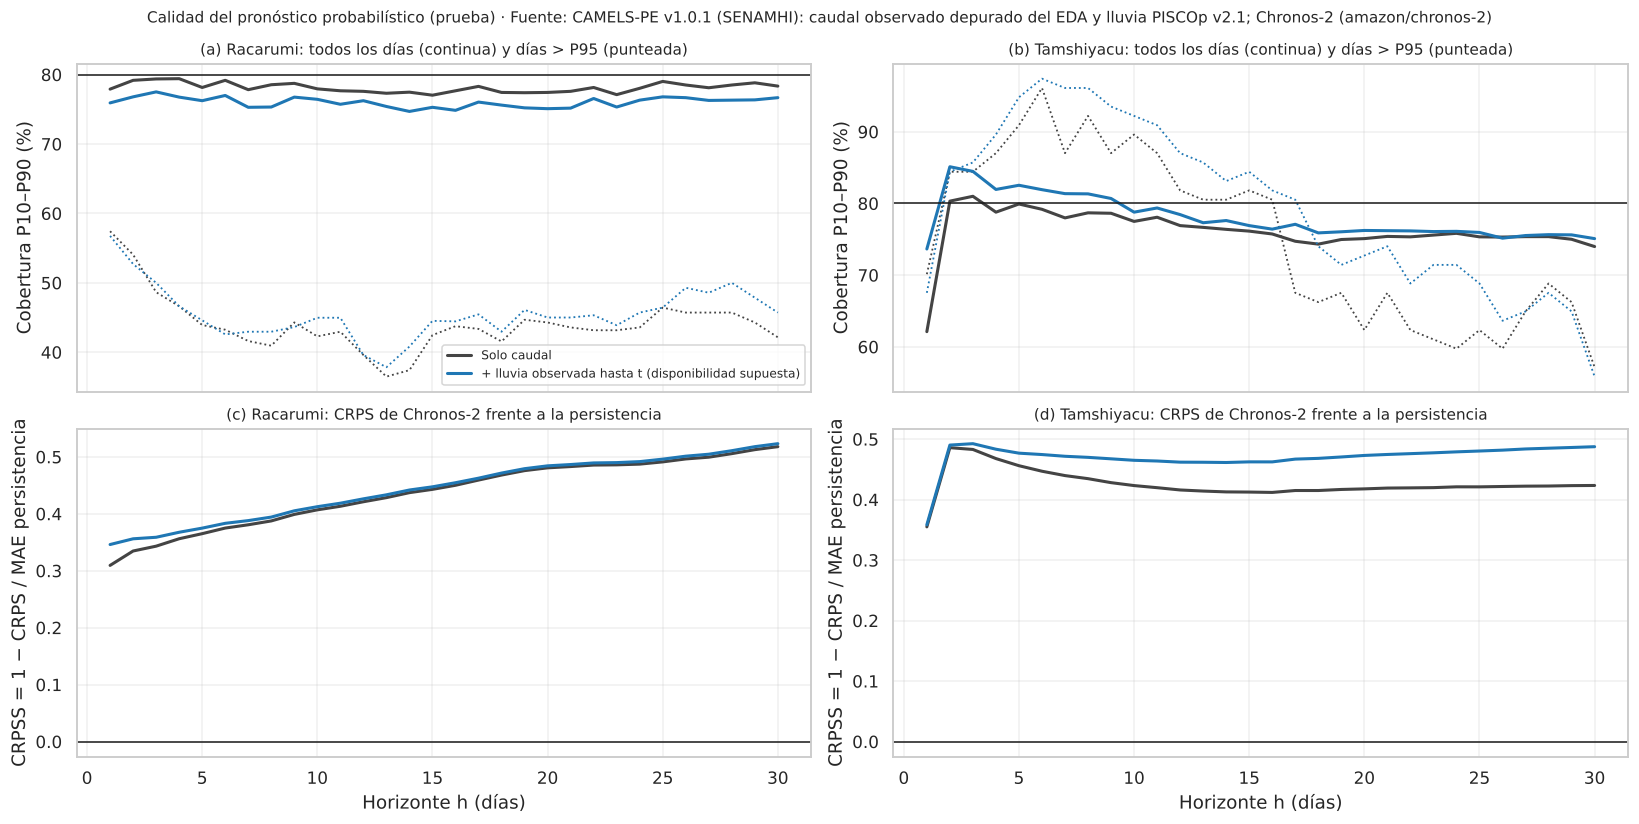

In [8]:
COLV = {V0: '#444444', V1: '#1f77b4'}
fig, ax = plt.subplots(2, 2, figsize=(15, 7.6), sharex=True)
for j, e in enumerate(EST):
    for _, _, _, et in VAR_P:
        ax[0, j].plot(hh, COB[(e, et)]['P10–P90'] * 100, color=COLV[et], lw=2, label=et)
        ax[0, j].plot(hh, COB[(e, et)]['P10–P90 en días > P95'] * 100, color=COLV[et], lw=1.2, ls=':')
        ax[1, j].plot(hh, CRPS[(e, et)]['CRPSS frente a la persistencia'], color=COLV[et], lw=2, label=et)
    ax[0, j].axhline(80, color='k', lw=1)
    ax[0, j].set_ylabel('Cobertura P10–P90 (%)'); ax[0, j].set_title(f"({'ab'[j]}) {e}: todos los días (continua) y días > P95 (punteada)", fontsize=10)
    ax[1, j].axhline(0, color='k', lw=1); ax[1, j].set_ylabel('CRPSS = 1 − CRPS / MAE persistencia'); ax[1, j].set_xlabel('Horizonte h (días)')
    ax[1, j].set_title(f"({'cd'[j]}) {e}: CRPS de Chronos-2 frente a la persistencia", fontsize=10)
    for a in ax[:, j]:
        a.grid(True, alpha=0.3)
ax[0, 0].legend(fontsize=8)
fig.suptitle('Calidad del pronóstico probabilístico (prueba) · ' + FUENTE, fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_probabilistico.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a, b)** Las curvas continuas oscilan cerca de 80 % salvo el primer día de Tamshiyacu; las punteadas (días sobre el P95) quedan en 42–57 % en Racarumi (42–50 % desde 3 días), y en Tamshiyacu se mantienen en 56–96 % según el horizonte (77 días altos de 3 crecidas).
- **(c, d)** La habilidad frente a la persistencia crece con el horizonte en Racarumi (de 0.31 a 0.52) porque la persistencia se degrada rápido; en Tamshiyacu se mantiene en 0.36–0.49. La lluvia la sube poco.

**Figura 2.** Bandas de pronóstico en dos crecidas de la prueba: Racarumi en el Niño costero de 2017 (a 1 y 3 días, con y sin lluvia) y Tamshiyacu en la crecida de 2021–2022 (a 15 días).

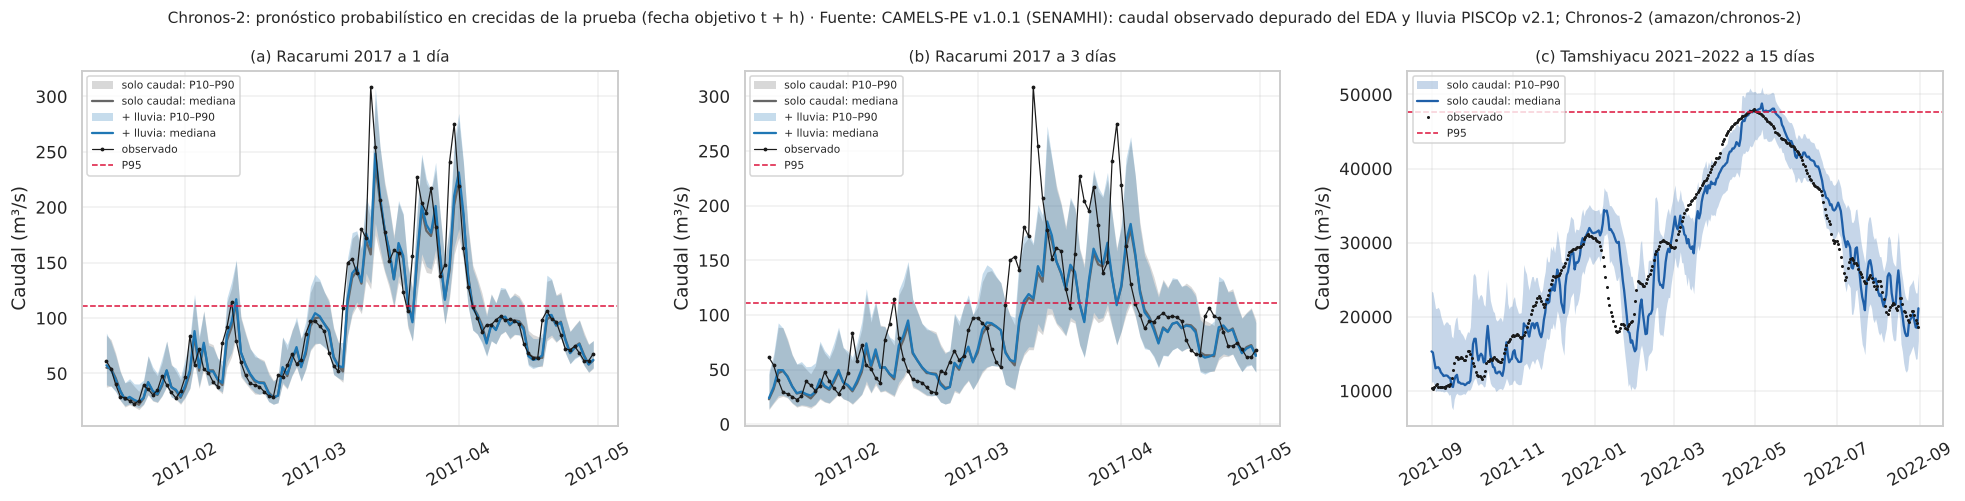

In [9]:
def banda(a, e, conj, h, d0, d1, col, et):
    d = D[e]; fp = d['m'].fechas[d['ip']]
    Q = sub(e, conj, 0, fp, 'cuantiles')
    fo = fp + pd.Timedelta(days=h)
    s = (fo >= d0) & (fo <= d1)
    a.fill_between(fo[s], CH.cuantil(Q, 0.1)[s, h - 1], CH.cuantil(Q, 0.9)[s, h - 1], color=col, alpha=0.25, lw=0, label=f'{et}: P10–P90')
    a.plot(fo[s], CH.cuantil(Q, 0.5)[s, h - 1], color=col, lw=1.5, label=f'{et}: mediana')
    return fo, s
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for a, h in zip(ax[:2], [1, 3]):
    fo, s = banda(a, 'Racarumi', 'Q', h, '2017-01-15', '2017-04-30', '0.4', 'solo caudal')
    banda(a, 'Racarumi', 'Q+P', h, '2017-01-15', '2017-04-30', COLV[V1], '+ lluvia')
    dR_ = D['Racarumi']
    a.plot(fo[s], dR_['m'].q_obs[dR_['ip']][s, h - 1], 'k.-', ms=3, lw=0.8, label='observado')
    a.axhline(dR_['P95'], color='crimson', ls='--', lw=1, label='P95')
    a.set_title(f"({'ab'[h > 1]}) Racarumi 2017 a {h} día{'s' if h > 1 else ''}", fontsize=10)
fo, s = banda(ax[2], 'Tamshiyacu', 'Q', 15, '2021-09-01', '2022-08-31', COLE['Tamshiyacu'], 'solo caudal')
ax[2].plot(fo[s], dT['m'].q_obs[dT['ip']][s, 14], 'k.', ms=2, label='observado'); ax[2].axhline(dT['P95'], color='crimson', ls='--', lw=1, label='P95')
ax[2].set_title('(c) Tamshiyacu 2021–2022 a 15 días', fontsize=10)
for a in ax:
    a.set_ylabel('Caudal (m³/s)'); a.legend(fontsize=7); a.grid(True, alpha=0.3)
    a.xaxis.set_major_locator(mdates.MonthLocator(interval=1 if a is not ax[2] else 2)); a.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')); a.tick_params(axis='x', labelrotation=30)
fig.suptitle('Chronos-2: pronóstico probabilístico en crecidas de la prueba (fecha objetivo t + h) · ' + FUENTE, fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_bandas_crecidas.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a) Racarumi a 1 día:** la mediana sigue cada pico de 2017, pero se queda corta en los mayores. Con y sin lluvia las bandas casi se superponen: la lluvia cambia poco el pronóstico de Chronos-2.
- **(b) Racarumi a 3 días:** la banda es ancha y aun así los picos mayores quedan por encima; la mediana llega tarde a cada crecida.
- **(c) Tamshiyacu a 15 días:** la mediana sigue la subida de 2021–2022 y la banda contiene el pico de mayo de 2022; la bajada brusca de enero–febrero de 2022 no se anticipa.

---
## 6. Sensibilidad posterior: ¿limitó el contexto a Tamshiyacu?
La prueba de Tamshiyacu, solo caudal, se repite con **2048 días** de contexto y se compara con el contexto elegido (512 días).
**Por qué (análisis agregado después de ver la prueba):** en 2012–2015 los contextos de 1024 y 2048 días se cortaban en el último escalón de nivel (hay escalones hasta 2014), así que la regla no pudo distinguirlos y eligió el más corto. **No cambia el contexto elegido** ni ninguna predicción que use el 08: es una sensibilidad informativa.

In [10]:
fT = dT['m'].fechas[dT['ip']]; oT = dT['m'].q_obs[dT['ip']]
persT, climT = C.pred_persistencia(dT['m'], dT['ip']), C.pred_climatologia(dT['m'], dT['ip'], C.climatologia_referencia(dT['q'], 'prueba'))
Q2048 = pronostico('Tamshiyacu', V0, fT, 2048)
p512, p2048 = sub('Tamshiyacu', 'Q', 0, fT), CH.punto(Q2048, PT['Tamshiyacu'])
filas_s = []
for et, pr in [(f"{CTX['Tamshiyacu']} d (elegido en validación)", p512), ('2048 d', p2048)]:
    t = C.tabla_metricas(oT, pr, persT, climT)
    hz = C.horizontes(t, C.bootstrap_curvas(fT, oT, pr, persT, climT, B=B))
    filas_s.append({'contexto': et, 'NSE medio': C.nse_medio(pr, oT), 'H cota 95 % (d)': hz['H_cota'], **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}})
sens = pd.DataFrame(filas_s).set_index('contexto')
_, sens_g = A.ganancia(fT, oT, p2048, p512, B=B)
sens.to_csv(RUTA_TAB / 'tabla_sensibilidad_contexto_tamshiyacu.csv'); sens_g.to_csv(RUTA_TAB / 'tabla_sensibilidad_contexto_tamshiyacu_ganancia.csv')
display(sens.round(3))
sens_g.round(3)

,NSE medio,H cota 95 % (d),NSE h=1,NSE h=7,NSE h=15,NSE h=30
contexto,,,,,,
512 d (elegido en validación),0.854,18,0.999,0.962,0.866,0.665
2048 d,0.899,25,0.998,0.967,0.897,0.801


,G,IC90 inferior,IC90 superior,lectura
banda,,,,
1–3 días,0.023,-0.023,0.066,sin diferencia demostrada
4–7 días,0.116,0.069,0.161,reduce el error
8–15 días,0.201,0.131,0.258,reduce el error
16–30 días,0.337,0.247,0.415,reduce el error


**Interpretación (sensibilidad posterior; no cambia lo elegido ni lo que usa el 08):**
- **Buena parte de la desventaja de Chronos-2 en Tamshiyacu viene del contexto corto.** Con 2 048 días el NSE medio sube de 0.854 a **0.899** y el horizonte útil de 18 a **25 días**; el error baja 12 % a 4–7 días, 20 % a 8–15 y 34 % a 16–30 (IC 90 % > 0), y a 30 días el NSE pasa de 0.665 a 0.801.
- **Lección de protocolo:** en el Amazonas el contexto debe abarcar varios años, pero la validación de 2012–2015 no pudo mostrarlo porque los escalones de nivel cortaban la historia. El 08 compara a Chronos-2 con el contexto elegido en validación (512 días), como fija el protocolo; con otro tratamiento de los escalones su resultado en Tamshiyacu podría ser mejor.

---
## 7. Escenario idealizado: lluvia futura observada (aparte de toda selección)
**Escenario idealizado:** con la lluvia observada de t+1 a t+30 como covariable futura (un pronóstico de lluvia perfecto, no disponible al emitir), cuánto cambia el error de Chronos-2 frente a solo caudal (G por bandas con IC 90 %) y qué avisos de nuevos cruces del P95 daría en Racarumi con las reglas del cuaderno 04 (regla calibrada en la validación). **No es una configuración utilizable y no participa en ninguna selección**; la comparación con los modelos entrenados en este mismo escenario está en el 08 (sección 8).

In [11]:
filas_i, AV_IDEAL = [], {}
for e in EST:
    d = D[e]; m, ip = d['m'], d['ip']; fp, obs = m.fechas[ip], m.q_obs[ip]
    pi, p0 = sub(e, 'Q+P', 0, fp, idealizado=True), sub(e, 'Q', 0, fp)
    pers, cl = C.pred_persistencia(m, ip), C.pred_climatologia(m, ip, C.climatologia_referencia(d['q'], 'prueba'))
    hz = C.horizontes(C.tabla_metricas(obs, pi, pers, cl), C.bootstrap_curvas(fp, obs, pi, pers, cl, B=B))
    _, gb = A.ganancia(fp, obs, pi, p0, B=B)
    for banda, g in gb.iterrows():
        filas_i.append({'estación': e, 'banda': banda, 'NSE medio idealizado': C.nse_medio(pi, obs), 'H cota 95 % idealizado (d)': hz['H_cota'], **g.to_dict()})
ideal = pd.DataFrame(filas_i).set_index(['estación', 'banda'])
ideal.to_csv(RUTA_TAB / 'tabla_idealizado.csv')
# Avisos en Racarumi con lluvia futura observada (configuración evaluada; regla calibrada en la validación)
fv, fpR = dR['m'].fechas[dR['iv']], dR['m'].fechas[dR['ip']]
cal = I.calibrar_regla(fv, sub('Racarumi', 'Q+P', 0, fv, 'mediana', True), dR['q'], dR['P95'])
AVI_ID = C.evaluar_avisos(fpR, sub('Racarumi', 'Q+P', 0, fpR, 'mediana', True), dR['q'], dR['P95'], f=cal['f'], hmax=cal['hmax'],
                          tol=C.AVISO['tol'], dmax=C.AVISO['dmax'], reinicio=C.AVISO['reinicio'])
av_ideal = pd.DataFrame([{'configuración': 'Chronos-2 · Q + lluvia futura observada (idealizado)', **I.fila_avisos(AVI_ID['resumen'])}]).set_index('configuración')
av_ideal.to_csv(RUTA_TAB / 'tabla_avisos_idealizado_racarumi.csv')
display(ideal.round(3))
av_ideal.drop(columns=['CSI IC90 inferior', 'CSI IC90 superior']).T

NSE medio idealizado  H cota 95 % idealizado (d)  \
estación   banda                                                          
Racarumi   1–3 días                   0.818                          30   
           4–7 días                   0.818                          30   
           8–15 días                  0.818                          30   
           16–30 días                 0.818                          30   
Tamshiyacu 1–3 días                   0.888                          22   
           4–7 días                   0.888                          22   
           8–15 días                  0.888                          22   
           16–30 días                 0.888                          22   

                           G  IC90 inferior  IC90 superior  \
estación   banda                                             
Racarumi   1–3 días    0.454          0.415          0.501   
           4–7 días    0.604          0.569          0.642   
           8–15 días   0.672          0.618          0.723   
           16–30 días  0.653          0.566          0.717   
Tamshiyacu 1–3 días   -0.010         -0.045          0.025   
           4–7 días    0.089          0.055          0.124   
           8–15 días   0.181          0.135          0.227   
           16–30 días  0.249          0.183          0.310   

                                         lectura  
estación   banda                                  
Racarumi   1–3 días              reduce el error  
           4–7 días              reduce el error  
           8–15 días             reduce el error  
           16–30 días            reduce el error  
Tamshiyacu 1–3 días    sin diferencia demostrada  
           4–7 días              reduce el error  
           8–15 días             reduce el error  
           16–30 días            reduce el error

configuración,Chronos-2 · Q + lluvia futura observada (idealizado)
f,0.9
h_max,30
cruces evaluables,32
aciertos,20
omisiones,12
falsas alarmas,8
POD,0.625
POD IC90,0.48–0.75
FAR,0.285714
FAR IC90,0.17–0.44


**Interpretación (escenario idealizado, aparte de toda selección):**
- **Racarumi:** con la lluvia futura observada, el error de Chronos-2 baja 45 % a 1–3 días y 60–67 % desde 4 días frente a su pronóstico con solo caudal, y el horizonte útil llega a ≥ 30 días (NSE medio 0.818).
- **Tamshiyacu:** nada a 1–3 días (la lluvia de esos días aún no llegó a la estación) y 9 %, 18 % y 25 % a 4–7, 8–15 y 16–30 días; horizonte útil de 22 días (NSE medio 0.888).
- **Avisos en Racarumi:** 20 de 32 cruces con 8 falsas alarmas (FAR 0.29) y anticipación útil de 9 días con el denominador variable, pero **2 días con el conjunto fijo de 32 cruces** (a 9 días solo una parte de los cruces es evaluable); con los IC no se cumple ni a 1 día (POD 0.48–0.75).
- La comparación con XGBoost y la regresión lineal en este mismo escenario está en el 08 (sección 8). Es un potencial con una lluvia futura sin error, no un pronóstico operativo.

---
## 8. Racarumi y Cirato (exploratorio)
En las emisiones de prueba desde 2022-10 con la ventana de Cirato completa, Chronos-2 con y sin Cirato a 1–7 días. A diferencia de los modelos entrenados, Chronos-2 puede usar una estación con un registro corto, porque no necesita años de datos para ajustar pesos. **Exploratorio:** menos de un año de emisiones y una sola temporada de lluvias; no hay bloque de validación con Cirato, así que no participa en ninguna selección (cuadernos 05 y 08).

In [12]:
rR = dR['m'].fechas[dR['ip']].get_indexer(F_CI)
obs_c = dR['m'].q_obs[dR['ip']][rR]
p_sin, p_con = sub('Racarumi', 'Q', 0, F_CI), sub('Racarumi', 'Q+A:Cirato', 0, F_CI)
gh_c, _ = A.ganancia(F_CI, obs_c, p_con, p_sin, B=B)
pers_c = C.pred_persistencia(dR['m'], dR['ip'])[rR]
ci = pd.DataFrame({'NSE sin Cirato': [C.nse(obs_c[:, h - 1], p_sin[:, h - 1]) for h in (1, 2, 3, 7)],
                   'NSE con Cirato': [C.nse(obs_c[:, h - 1], p_con[:, h - 1]) for h in (1, 2, 3, 7)],
                   'NSE persistencia': [C.nse(obs_c[:, h - 1], pers_c[:, h - 1]) for h in (1, 2, 3, 7)],
                   'G con Cirato': gh_c.loc[[1, 2, 3, 7], 'G'].values, 'IC90 inferior': gh_c.loc[[1, 2, 3, 7], 'IC90 inferior'].values,
                   'IC90 superior': gh_c.loc[[1, 2, 3, 7], 'IC90 superior'].values, 'lectura': gh_c.loc[[1, 2, 3, 7], 'lectura'].values},
                  index=pd.Index([1, 2, 3, 7], name='h'))
ci.to_csv(RUTA_TAB / 'tabla_cirato.csv')
print(f"{len(F_CI)} emisiones ({F_CI.min():%Y-%m-%d} a {F_CI.max():%Y-%m-%d}), {F_CI.to_period('M').nunique()} meses")
ci.round(3)

197 emisiones (2022-10-07 a 2023-08-01), 10 meses


,NSE sin Cirato,NSE con Cirato,NSE persistencia,G con Cirato,IC90 inferior,IC90 superior,lectura
h,,,,,,,
1,0.785,0.783,0.774,-0.010,-0.014,0.005,sin diferencia demostrada
2,0.568,0.566,0.538,-0.004,-0.009,0.009,sin diferencia demostrada
3,0.427,0.428,0.350,0.001,-0.008,0.022,sin diferencia demostrada
7,0.136,0.141,-0.382,0.005,-0.005,0.022,sin diferencia demostrada


**Interpretación (exploratoria):**
- **Cirato no mejora a Chronos-2** en las 197 emisiones disponibles (2022-10 a 2023-08): G = −1.0 % a 1 día, −0.4 % a 2 días, +0.1 % a 3 días y +0.5 % a 7 días, todos sin diferencia demostrada. Coincide con los seis modelos entrenados del cuaderno 05.
- **Por qué es razonable:** el desfase de máxima asociación entre Cirato y Racarumi es 0 días (tránsito estimado de 3 a 15 horas); el día t las dos estaciones ya cambiaron casi a la vez.
- **Lo propio de Chronos-2:** puede probar una estación con un registro corto (aquí, dos meses de Cirato en el contexto) sin ajustar pesos. La respuesta es negativa, pero el procedimiento sirve para estaciones nuevas.

---
## 9. Resumen para el informe
Archivos de salida: `salidas/chronos/resumen.json` (configuración elegida, verificación de la caché y cifras propias de Chronos-2) y `salidas/chronos/predicciones.npz` las predicciones de todas las combinaciones (puntual, mediana, P10 y P90 por emisión) que lee el 08. La caché completa de cuantiles queda en `salidas/chronos/cache/` (no se sube a GitHub).

In [13]:
resumen = {
    'version': C.VERSION, 'revision': C.REVISION, 'rapido': RAPIDO, 'metodo': 'Chronos-2 con los pesos publicados, sin ajuste local (amazon/chronos-2)',
    'modelo_origen': ORIGEN['origen'], 'modelo_commit': ORIGEN['commit'], 'sha256_model_safetensors': HUELLA_PESOS, 'huella_archivos_modelo': HUELLA,
    'software': CH.software(), 'contexto_dias': CTX, 'pronostico_puntual': PT,
    'combinaciones': [f"{e}|{c}" for e, c in plan.index],
    'auditoria_cache': {'combinaciones': int(len(plan)), 'reutilizadas': int(plan[COL_R].sum()),
                        'calculadas': int((~plan[COL_R]).sum()),
                        'calculadas_lista': [f"{e}|{c}" for (e, c), r in plan.iterrows() if not r[COL_R]],
                        'descartadas': [f"{e}|{c}: {r['estado de la caché']}" for (e, c), r in plan.iterrows() if str(r['estado de la caché']).startswith('descartada')],
                        'cachés verificadas (incluye contexto)': int(aud['reutilizada de la caché'].sum()),
                        'dif_relativa_max_reproduccion': float(aud['dif. relativa máx.'].max())},
    'emisiones': {'Tamshiyacu con San Regis': len(F_SR), 'Tamshiyacu con Requena': len(F_RQ), 'Cirato': int(len(F_CI))},
    'cobertura_P10_P90': {f'{e} | {v}': {int(h): round(float(COB[(e, v)].loc[h, 'P10–P90']), 3) for h in H_CLAVE[e]} for e, v in COB},
    'cobertura_P10_P90_dias_altos': {f'{e} | {v}': {int(h): round(float(COB[(e, v)].loc[h, 'P10–P90 en días > P95']), 3) for h in H_CLAVE[e]} for e, v in COB},
    'sensibilidad_contexto_tamshiyacu': {k: round(float(v), 4) for k, v in sens['NSE medio'].items()},
    'idealizado': {f'{e} | {b}': round(float(ideal.loc[(e, b), 'G']), 3) for e, b in ideal.index},
    'avisos_idealizado_racarumi': {k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in AVI_ID['resumen'].items()
                                   if k in ['f', 'hmax', 'evaluables', 'aciertos', 'falsas_alarmas', 'POD', 'FAR', 'CSI', 'anticipacion_util', 'anticipacion_util_conjunto_fijo']},
    'cirato': {'emisiones': int(len(F_CI)), 'G h1': round(float(ci.loc[1, 'G con Cirato']), 3), 'lectura h1': ci.loc[1, 'lectura']},
    'minutos': round((time.time() - T_INICIO) / 60, 1),
}
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(f"Tiempo total: {resumen['minutos']} min")
print(json.dumps({k: resumen[k] for k in ['contexto_dias', 'pronostico_puntual', 'auditoria_cache']}, ensure_ascii=False, indent=1))

Tiempo total: 1.7 min
{
 "contexto_dias": {
  "Racarumi": 2048,
  "Tamshiyacu": 512
 },
 "pronostico_puntual": {
  "Racarumi": "media",
  "Tamshiyacu": "media"
 },
 "auditoria_cache": {
  "combinaciones": 31,
  "reutilizadas": 31,
  "calculadas": 0,
  "calculadas_lista": [],
  "descartadas": [],
  "cachés verificadas (incluye contexto)": 37,
  "dif_relativa_max_reproduccion": 6.744575671291386e-07
 }
}


---
## 10. Conclusiones

1. **Este cuaderno produce las predicciones de Chronos-2 para la comparación integrada del 08** con las mismas emisiones y las mismas fuentes y disponibilidad que los modelos entrenados (con su propia representación: series diarias en unidades físicas): 28 combinaciones (Racarumi: Q, Q+P y Q+P+IA; Tamshiyacu: las 12 combinaciones de lluvia, índices, San Regis y Requena), cada una con las fuentes externas hasta t y hasta t−1. **Cada predicción reutilizada se verificó por identidad, contenido y reproducción de una muestra de emisiones** (37 cachés, diferencia relativa máxima 6.7·10⁻⁷, ninguna descartada). Ninguna entrada del 08 quedó sin representar.
2. **Lo único que se elige aquí, en validación, es el contexto y el pronóstico puntual:** 2 048 días y la media en Racarumi; 512 días y la media en Tamshiyacu, donde los escalones de nivel de 2012–2015 impidieron distinguir contextos. Con 2 048 días Tamshiyacu mejoraría mucho (NSE medio 0.854 → 0.899; sensibilidad posterior que no cambia lo elegido).
3. **El pronóstico probabilístico de Chronos-2 tiene una cobertura agregada cercana a la nominal en Racarumi (77–79 % para P10–P90) pero baja a 42–57 % en los días sobre el P95**, y en Tamshiyacu sus bandas son demasiado estrechas a 1 día (62 %). Su CRPS es 31–52 % menor que el error absoluto de la persistencia.
4. **Con la lluvia futura observada (idealizado)** Chronos-2 reduce su error 45–67 % en Racarumi y llega a 9 días de anticipación útil con el denominador variable (2 con el conjunto fijo de cruces). **Cirato no lo mejora** (exploratorio).
5. **Si Chronos-2 es mejor o peor que los modelos entrenados, y si se elige como configuración final, se decide en el 08** con el protocolo común, en las mismas emisiones y con las mismas reglas de selección.

### Limitaciones
- **Sin ajuste local no es "sin datos":** se usa la historia de la estación como contexto y se eligen el contexto y el pronóstico puntual en validación. No se puede descartar que el preentrenamiento incluya series de caudal del Perú.
- **Contexto de Tamshiyacu limitado por los escalones de nivel** en el bloque de selección (sección 6).
- **Representación distinta:** Chronos-2 recibe la serie diaria completa de cada covariable dentro de su contexto, en unidades físicas, no los resúmenes en logaritmos de los modelos tabulares (tabla de entradas reales, sección 4); los índices antecedentes son funciones de la lluvia que ya ve.
- **Costo:** con cuatro covariables y 2 048 días de contexto, más de una hora por combinación en CPU.
- **Uso previo de la prueba:** el periodo de prueba (desde 2016-01) se consultó durante el desarrollo del proyecto con Chronos-2 y la mayoría de estas entradas.